# Notebook 01 — Goodbooks-10k Data Preparation and Dataset Audit

**Research project:** *An Integrated Graph Theory, Linear Programming, and Machine Learning Approach to Community Detection and Optimization in Book Networks Using Goodbooks-10k*

**Purpose of this notebook:** inspect the supplied dataset, load the CSV files, validate identifiers and data quality, prepare book-tag information for graph construction, and create a clean rating table for the later ML experiment. This notebook does **not** build the graph or train models yet.

### Expected files
The uploaded `archive.zip` contains `books.csv`, `book_tags.csv`, `ratings.csv`, `tags.csv`, and `to_read.csv`. Keep `archive.zip` in the project root or inside a `data/` folder. The notebook will look for it and extract the CSVs into `data/raw/` automatically.

### Reproducibility notes
- The original CSV files are not overwritten.
- Derived files are saved to `data/processed/` and summary reports to `outputs/`.
- Full `ratings.csv` can be large. We inspect it fully for counts and validity, but do not print the full table.
- The dataset has two different book identifiers: `books.csv.id` is the dataset's 1–10,000 row identifier, while `books.csv.book_id` / `best_book_id` are Goodreads IDs. `book_tags.csv.goodreads_book_id` uses Goodreads IDs; `ratings.csv.book_id` uses the dataset book ID. We preserve this distinction carefully.

## 1. Imports and configuration

In [1]:

from pathlib import Path
import zipfile
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

RANDOM_STATE = 42

# Find the project root from the notebook's current working directory
cwd = Path.cwd().resolve()

if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
elif (cwd / "notebooks").is_dir():
    PROJECT_ROOT = cwd
else:
    raise FileNotFoundError(
        f"Could not identify the project root. Current directory: {cwd}"
    )

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

for folder in [RAW_DIR, PROCESSED_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder:", RAW_DIR)
print("Processed data folder:", PROCESSED_DIR)
print("Outputs folder:", OUTPUT_DIR)


Project root: C:\Users\Nethmi\Desktop\goodbooks-graph-research
Raw data folder: C:\Users\Nethmi\Desktop\goodbooks-graph-research\data\raw
Processed data folder: C:\Users\Nethmi\Desktop\goodbooks-graph-research\data\processed
Outputs folder: C:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs


## 2. Find and extract the supplied archive

In [2]:
# Search common locations. If you extracted the archive yourself, the notebook can also use CSVs already in data/raw/ or data/.
archive_candidates = [
    PROJECT_ROOT / "archive.zip",
    DATA_DIR / "archive.zip",
    PROJECT_ROOT / "data.zip",
]
archive_path = next((p for p in archive_candidates if p.exists()), None)

expected_files = ["books.csv", "book_tags.csv", "ratings.csv", "tags.csv", "to_read.csv"]

if archive_path is not None:
    print("Found archive:", archive_path.resolve())
    with zipfile.ZipFile(archive_path, "r") as zf:
        members = zf.namelist()
        print("Archive members:", members)
        for filename in expected_files:
            matches = [m for m in members if Path(m).name == filename]
            if matches:
                # Extract only the expected CSV by basename, avoiding unrelated archive paths.
                target = RAW_DIR / filename
                with zf.open(matches[0]) as src, open(target, "wb") as dst:
                    dst.write(src.read())
else:
    print("No archive found in the common locations. Checking for CSVs already present...")
    for filename in expected_files:
        possible = [DATA_DIR / filename, PROJECT_ROOT / filename]
        existing = next((p for p in possible if p.exists()), None)
        if existing and existing != RAW_DIR / filename:
            import shutil
            shutil.copy2(existing, RAW_DIR / filename)

missing_files = [f for f in expected_files if not (RAW_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(
        f"Missing files: {missing_files}. Put archive.zip in the project root or data/ folder, "
        "or place the CSVs in data/ or the project root, then rerun this cell."
    )

print("\nFiles ready:")
for filename in expected_files:
    path = RAW_DIR / filename
    print(f"- {filename}: {path.stat().st_size / (1024**2):.2f} MB")

No archive found in the common locations. Checking for CSVs already present...

Files ready:
- books.csv: 3.14 MB
- book_tags.csv: 15.89 MB
- ratings.csv: 11.86 MB
- tags.csv: 0.69 MB
- to_read.csv: 8.97 MB


## 3. Load the CSV files

In [3]:
books = pd.read_csv(RAW_DIR / "books.csv")
book_tags = pd.read_csv(RAW_DIR / "book_tags.csv")
ratings = pd.read_csv(RAW_DIR / "ratings.csv")
tags = pd.read_csv(RAW_DIR / "tags.csv")
to_read = pd.read_csv(RAW_DIR / "to_read.csv")

frames = {
    "books": books,
    "book_tags": book_tags,
    "ratings": ratings,
    "tags": tags,
    "to_read": to_read,
}

shape_summary = pd.DataFrame([
    {"dataset": name, "rows": df.shape[0], "columns": df.shape[1], "memory_MB": round(df.memory_usage(deep=True).sum() / (1024**2), 2)}
    for name, df in frames.items()
]).set_index("dataset")
shape_summary

,rows,columns,memory_MB
dataset,,,
books,10000,23,7.09
book_tags,999912,3,22.89
ratings,981756,3,22.47
tags,34252,2,2.59
to_read,912705,2,13.93


In [4]:
for name, df in frames.items():
    print(f"\n{name.upper()} — columns")
    print(df.dtypes.to_string())
    display(df.head(3))


BOOKS — columns
id                             int64
book_id                        int64
best_book_id                   int64
work_id                        int64
books_count                    int64
isbn                             str
isbn13                       float64
authors                          str
original_publication_year    float64
original_title                   str
title                            str
language_code                    str
average_rating               float64
ratings_count                  int64
work_ratings_count             int64
work_text_reviews_count        int64
ratings_1                      int64
ratings_2                      int64
ratings_3                      int64
ratings_4                      int64
ratings_5                      int64
image_url                        str
small_image_url                  str


,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,title,language_code,average_rating,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",eng,4.34,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m/2767052.jpg,https://images.gr-assets.com/books/1447303603s/2767052.jpg
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)",eng,4.44,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m/3.jpg,https://images.gr-assets.com/books/1474154022s/3.jpg
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,"Twilight (Twilight, #1)",en-US,3.57,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m/41865.jpg,https://images.gr-assets.com/books/1361039443s/41865.jpg



BOOK_TAGS — columns
goodreads_book_id    int64
tag_id               int64
count                int64


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173



RATINGS — columns
book_id    int64
user_id    int64
rating     int64


,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5



TAGS — columns
tag_id      int64
tag_name      str


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-



TO_READ — columns
user_id    int64
book_id    int64


,user_id,book_id
0,1,112
1,1,235
2,1,533


## 4. Validate expected schemas and identifier meanings

In [5]:
required_columns = {
    "books": {"id", "book_id", "best_book_id", "title", "authors", "average_rating", "ratings_count"},
    "book_tags": {"goodreads_book_id", "tag_id", "count"},
    "ratings": {"book_id", "user_id", "rating"},
    "tags": {"tag_id", "tag_name"},
    "to_read": {"user_id", "book_id"},
}

schema_check = []
for name, required in required_columns.items():
    actual = set(frames[name].columns)
    schema_check.append({
        "dataset": name,
        "required_columns_present": required.issubset(actual),
        "missing_required_columns": sorted(required - actual),
    })
display(pd.DataFrame(schema_check))

# Identifier notes for later notebooks:
# - books.id maps to ratings.book_id and to_read.book_id.
# - books.book_id / books.best_book_id map to book_tags.goodreads_book_id.
# - book_tags.tag_id maps to tags.tag_id.
print("Books dataset IDs unique:", books["id"].is_unique)
print("Books Goodreads IDs unique:", books["book_id"].is_unique)
print("Book-tag pairs unique:", not book_tags.duplicated(["goodreads_book_id", "tag_id"]).any())
print("Rating user-book pairs unique:", not ratings.duplicated(["user_id", "book_id"]).any())

,dataset,required_columns_present,missing_required_columns
0,books,True,[]
1,book_tags,True,[]
2,ratings,True,[]
3,tags,True,[]
4,to_read,True,[]


Books dataset IDs unique: True
Books Goodreads IDs unique: True
Book-tag pairs unique: False
Rating user-book pairs unique: False


## 5. Data-quality audit

In [6]:
def quality_report(df, name):
    return {
        "dataset": name,
        "rows": len(df),
        "duplicate_rows": int(df.duplicated().sum()),
        "columns_with_missing_values": int(df.isna().any().sum()),
        "total_missing_cells": int(df.isna().sum().sum()),
    }

quality = pd.DataFrame([quality_report(df, name) for name, df in frames.items()])
display(quality)

missing_by_column = {}
for name, df in frames.items():
    miss = df.isna().sum()
    miss = miss[miss > 0].sort_values(ascending=False)
    missing_by_column[name] = miss
    print(f"\n{name}: missing values")
    display(miss.to_frame("missing_count") if len(miss) else pd.DataFrame({"message": ["No missing values"]}))

,dataset,rows,duplicate_rows,columns_with_missing_values,total_missing_cells
0,books,10000,0,5,2975
1,book_tags,999912,6,0,0
2,ratings,981756,1644,0,0
3,tags,34252,0,0,0
4,to_read,912705,0,0,0



books: missing values


,missing_count
language_code,1084
isbn,700
isbn13,585
original_title,585
original_publication_year,21



book_tags: missing values


,message
0,No missing values



ratings: missing values


,message
0,No missing values



tags: missing values


,message
0,No missing values



to_read: missing values


,message
0,No missing values


In [7]:
# Check rating values and count fields.
print("Rating value counts:")
display(ratings["rating"].value_counts(dropna=False).sort_index().to_frame("count"))

rating_valid = ratings["rating"].between(1, 5).all()
print("All ratings between 1 and 5:", bool(rating_valid))
print("Negative book-tag counts:", int((book_tags["count"] < 0).sum()))
print("Zero book-tag counts:", int((book_tags["count"] == 0).sum()))
print("Negative average ratings:", int((books["average_rating"] < 0).sum()))
print("Book IDs in ratings not in books.id:", int((~ratings["book_id"].isin(books["id"])).sum()))
print("Tag IDs in book_tags not in tags.tag_id:", int((~book_tags["tag_id"].isin(tags["tag_id"])).sum()))
print("Goodreads book IDs in book_tags not in books.book_id:", int((~book_tags["goodreads_book_id"].isin(books["book_id"])).sum()))

Rating value counts:


,count
rating,
1,19575
2,63231
3,248623
4,357366
5,292961


All ratings between 1 and 5: True
Negative book-tag counts: 6
Zero book-tag counts: 0
Negative average ratings: 0
Book IDs in ratings not in books.id: 0
Tag IDs in book_tags not in tags.tag_id: 0
Goodreads book IDs in book_tags not in books.book_id: 0


## 6. Remove exact duplicate rows and validate keys

For this research, remove exact duplicate rows from the derived working tables. Do not delete records simply because they look unusual. Report the duplicate counts first, and preserve the raw CSV files unchanged. The rating dataset should normally have one row per user-book pair; the following cell reports any repeated pairs separately because these require inspection rather than silent aggregation.

In [8]:
books_clean = books.drop_duplicates().copy()
book_tags_clean = book_tags.drop_duplicates().copy()
ratings_clean = ratings.drop_duplicates().copy()
tags_clean = tags.drop_duplicates().copy()
to_read_clean = to_read.drop_duplicates().copy()

# Keep only structurally valid records for derived analysis tables.
books_clean = books_clean.dropna(subset=["id", "book_id", "title"])
book_tags_clean = book_tags_clean.dropna(subset=["goodreads_book_id", "tag_id", "count"])
ratings_clean = ratings_clean.dropna(subset=["book_id", "user_id", "rating"])
tags_clean = tags_clean.dropna(subset=["tag_id", "tag_name"])
to_read_clean = to_read_clean.dropna(subset=["user_id", "book_id"])

# Standardize numeric ID/rating columns; raise if unexpected non-numeric values exist.
for col in ["id", "book_id", "best_book_id"]:
    books_clean[col] = pd.to_numeric(books_clean[col], errors="coerce")
for col in ["goodreads_book_id", "tag_id", "count"]:
    book_tags_clean[col] = pd.to_numeric(book_tags_clean[col], errors="coerce")
for col in ["book_id", "user_id", "rating"]:
    ratings_clean[col] = pd.to_numeric(ratings_clean[col], errors="coerce")
for col in ["tag_id"]:
    tags_clean[col] = pd.to_numeric(tags_clean[col], errors="coerce")
for col in ["user_id", "book_id"]:
    to_read_clean[col] = pd.to_numeric(to_read_clean[col], errors="coerce")

books_clean = books_clean.dropna(subset=["id", "book_id", "best_book_id"])
book_tags_clean = book_tags_clean.dropna(subset=["goodreads_book_id", "tag_id", "count"])
ratings_clean = ratings_clean.dropna(subset=["book_id", "user_id", "rating"])
tags_clean = tags_clean.dropna(subset=["tag_id"])
to_read_clean = to_read_clean.dropna(subset=["user_id", "book_id"])

# IDs and ratings should be integers in this dataset.
for col in ["id", "book_id", "best_book_id"]:
    books_clean[col] = books_clean[col].astype("int64")
for col in ["goodreads_book_id", "tag_id", "count"]:
    book_tags_clean[col] = book_tags_clean[col].astype("int64")
for col in ["book_id", "user_id", "rating"]:
    ratings_clean[col] = ratings_clean[col].astype("int64")
tags_clean["tag_id"] = tags_clean["tag_id"].astype("int64")
for col in ["user_id", "book_id"]:
    to_read_clean[col] = to_read_clean[col].astype("int64")

print("Rows before -> after exact deduplication / required-field cleaning")
for name, before, after in [
    ("books", books, books_clean),
    ("book_tags", book_tags, book_tags_clean),
    ("ratings", ratings, ratings_clean),
    ("tags", tags, tags_clean),
    ("to_read", to_read, to_read_clean),
]:
    print(f"{name:12s}: {len(before):,} -> {len(after):,}")

repeated_user_book = ratings_clean.duplicated(["user_id", "book_id"], keep=False).sum()
print("Rows participating in repeated user-book pairs:", int(repeated_user_book))
if repeated_user_book:
    print("Note: repeated user-book pairs are reported, not automatically aggregated.")

Rows before -> after exact deduplication / required-field cleaning
books       : 10,000 -> 10,000
book_tags   : 999,912 -> 999,906
ratings     : 981,756 -> 980,112
tags        : 34,252 -> 34,252
to_read     : 912,705 -> 912,705
Rows participating in repeated user-book pairs: 1267
Note: repeated user-book pairs are reported, not automatically aggregated.


## 7. Join book tags to tag names and book metadata

The tag file uses Goodreads book IDs, whereas the ratings file uses the dataset `books.id`. We use `books.book_id` to connect the tag records to the book metadata. This is a critical identifier mapping for the next Graph Theory notebook.

In [9]:
# Ensure join keys are well-defined.
book_metadata = books_clean.copy()
book_metadata = book_metadata.drop_duplicates(subset=["book_id"], keep="first")
tag_lookup = tags_clean.drop_duplicates(subset=["tag_id"], keep="first")

book_tags_named = book_tags_clean.merge(
    tag_lookup[["tag_id", "tag_name"]], on="tag_id", how="left", validate="many_to_one"
)
book_tags_named = book_tags_named.merge(
    book_metadata[["id", "book_id", "title", "authors", "language_code", "average_rating", "ratings_count"]],
    left_on="goodreads_book_id", right_on="book_id", how="left", suffixes=("_tag", "_book"), validate="many_to_one"
)

# The merged table retains unmatched tag rows for audit; count them before choosing the graph-ready table.
unmatched_book_tags = int(book_tags_named["id"].isna().sum())
unmatched_tag_names = int(book_tags_named["tag_name"].isna().sum())
print("Book-tag rows without matched book metadata:", unmatched_book_tags)
print("Book-tag rows without matched tag names:", unmatched_tag_names)
display(book_tags_named.head())

Book-tag rows without matched book metadata: 0
Book-tag rows without matched tag names: 0


,goodreads_book_id,tag_id,count,tag_name,id,book_id,title,authors,language_code,average_rating,ratings_count
0,1,30574,167697,to-read,27,1,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)","J.K. Rowling, Mary GrandPré",eng,4.54,1678823
1,1,11305,37174,fantasy,27,1,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)","J.K. Rowling, Mary GrandPré",eng,4.54,1678823
2,1,11557,34173,favorites,27,1,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)","J.K. Rowling, Mary GrandPré",eng,4.54,1678823
3,1,8717,12986,currently-reading,27,1,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)","J.K. Rowling, Mary GrandPré",eng,4.54,1678823
4,1,33114,12716,young-adult,27,1,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)","J.K. Rowling, Mary GrandPré",eng,4.54,1678823


## 8. Prepare graph-ready tag data

The graph notebook will decide which tags are sufficiently informative and which books to include. Here we create a clean base table and a compact per-book tag summary, but we do not yet apply final graph thresholds. The `count` column records how often a tag was applied to a book in the source data; it is not the same as the number of shared tags between two books.

In [10]:
# Retain matched book/tag rows with non-empty tag labels.
graph_tag_rows = book_tags_named.dropna(subset=["id", "goodreads_book_id", "tag_id", "tag_name"]).copy()
graph_tag_rows["tag_name"] = graph_tag_rows["tag_name"].astype(str).str.strip()
graph_tag_rows = graph_tag_rows[graph_tag_rows["tag_name"].ne("")]

# Remove duplicate book-tag relationships in case the source has repeated keys.
graph_tag_rows = graph_tag_rows.drop_duplicates(subset=["goodreads_book_id", "tag_id"])

per_book_tag_summary = (
    graph_tag_rows.groupby(["id", "goodreads_book_id", "title"], dropna=False)
    .agg(
        unique_tag_count=("tag_id", "nunique"),
        tag_application_count=("count", "sum"),
        example_tags=("tag_name", lambda s: ", ".join(list(dict.fromkeys(s.astype(str)))[:10]))
    )
    .reset_index()
    .sort_values("unique_tag_count", ascending=False)
)

display(per_book_tag_summary.head(10))
print("Books with at least one matched tag:", per_book_tag_summary["id"].nunique())
print("Graph-ready book-tag rows:", len(graph_tag_rows))

,id,goodreads_book_id,title,unique_tag_count,tag_application_count,example_tags
9983,9984,764165,The Snow Leopard,100,2846,"to-read, travel, non-fiction, favorites, nature, nonfiction, memoir, adventure, philosophy, curr..."
9982,9983,8539798,"Blue exorcist, Tome 2",100,3838,"to-read, manga, mangá, fantasy, favorites, currently-reading, blue-exorcist, owned, graphic-nove..."
9981,9982,12444298,"Feverborn (Fever, #8)",100,11303,"to-read, urban-fantasy, fantasy, paranormal, favorites, currently-reading, romance, paranormal-r..."
9980,9981,106312,"The Twelfth Card (Lincoln Rhyme, #6)",100,3198,"to-read, currently-reading, mystery, jeffery-deaver, thriller, default, fiction, crime, favorite..."
9979,9980,946899,The Measure of a Lady,100,7591,"to-read, christian-fiction, historical-fiction, romance, christian, historical, currently-readin..."
9978,9979,16951,"When the Lion Feeds (Courtney, #1)",100,1960,"to-read, currently-reading, historical-fiction, wilbur-smith, fiction, historical, favorites, af..."
9977,9978,162332,The Sailor Who Fell from Grace with the Sea,100,9473,"to-read, fiction, japan, currently-reading, japanese, favorites, japanese-literature, classics, ..."
9976,9977,202948,Ladder of Years,100,3778,"to-read, fiction, book-club, favorites, currently-reading, anne-tyler, contemporary-fiction, con..."
9975,9976,6351939,"Sea Glass (Glass, #2)",100,7656,"to-read, fantasy, young-adult, favorites, magic, books-i-own, romance, ya, series, currently-rea..."
9974,9975,613991,"The King Beyond the Gate (The Drenai Saga, #2)",100,1153,"to-read, currently-reading, default, fiction, fantasy, david-gemmell, owned, heroic-fantasy, fav..."


Books with at least one matched tag: 10000
Graph-ready book-tag rows: 999904


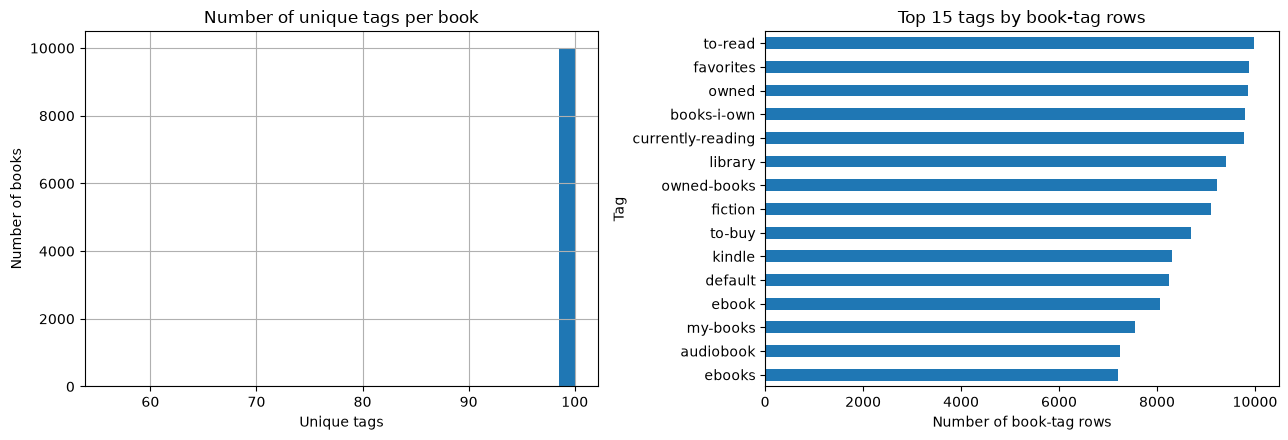

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
per_book_tag_summary["unique_tag_count"].hist(bins=30, ax=axes[0])
axes[0].set_title("Number of unique tags per book")
axes[0].set_xlabel("Unique tags")
axes[0].set_ylabel("Number of books")

top_tags = (graph_tag_rows.groupby("tag_name").size().sort_values(ascending=False).head(15).sort_values())
top_tags.plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 15 tags by book-tag rows")
axes[1].set_xlabel("Number of book-tag rows")
axes[1].set_ylabel("Tag")
plt.tight_layout()
plt.show()

## 9. Prepare the ratings table for the ML experiment

For the later classification experiment, we will initially define a positive rating as 4 or 5 and a non-positive rating as 1, 2 or 3. This threshold is a research design choice, not a property of the original dataset. The ML notebook must split ratings into train/test sets before learning any user or community preference features.

Rating rows without matched book metadata: 0
Ratings prepared: 980,112
Unique users: 53,424
Unique books rated: 10,000


,book_id,user_id,rating,id,title,authors,language_code,average_rating,ratings_count,positive_rating
0,1,314,5,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653,1
1,1,439,3,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653,0
2,1,588,5,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653,1
3,1,1169,4,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653,1
4,1,1185,4,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653,1


,label,count,percentage
0,Non-positive (rating 1–3),331041,33.78
1,Positive (rating 4–5),649071,66.22


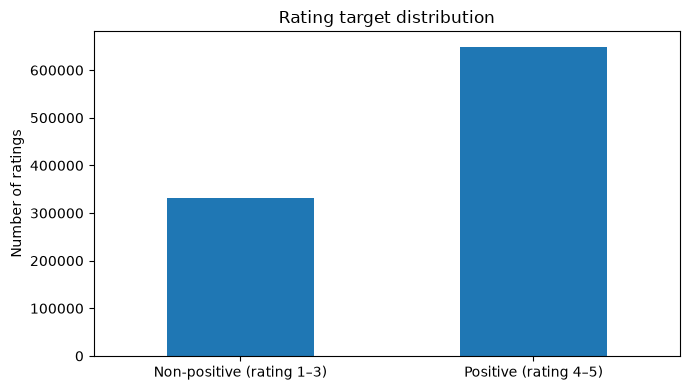

In [12]:
# Map ratings.book_id to books.id, then add basic book metadata.
ratings_model = ratings_clean.merge(
    book_metadata[["id", "title", "authors", "language_code", "average_rating", "ratings_count"]],
    left_on="book_id", right_on="id", how="left", validate="many_to_one"
)
ratings_model["positive_rating"] = (ratings_model["rating"] >= 4).astype("int8")

unmatched_rating_books = int(ratings_model["id"].isna().sum())
print("Rating rows without matched book metadata:", unmatched_rating_books)
print("Ratings prepared:", f"{len(ratings_model):,}")
print("Unique users:", f"{ratings_model['user_id'].nunique():,}")
print("Unique books rated:", f"{ratings_model['book_id'].nunique():,}")

display(ratings_model.head())

target_counts = ratings_model["positive_rating"].value_counts().sort_index()
target_summary = pd.DataFrame({
    "label": ["Non-positive (rating 1–3)", "Positive (rating 4–5)"],
    "count": [int(target_counts.get(0, 0)), int(target_counts.get(1, 0))],
})
target_summary["percentage"] = (target_summary["count"] / len(ratings_model) * 100).round(2)
display(target_summary)

ax = target_summary.set_index("label")["count"].plot(kind="bar", figsize=(7, 4))
ax.set_title("Rating target distribution")
ax.set_ylabel("Number of ratings")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Dataset coverage and join validation

In [13]:
# Compact validation summary for report documentation.
validation_summary = pd.DataFrame([
    {"check": "Books rows after cleaning", "value": len(books_clean)},
    {"check": "Unique dataset book IDs", "value": books_clean["id"].nunique()},
    {"check": "Unique Goodreads book IDs", "value": books_clean["book_id"].nunique()},
    {"check": "Unique tag IDs", "value": tags_clean["tag_id"].nunique()},
    {"check": "Clean book-tag relationships", "value": len(graph_tag_rows)},
    {"check": "Books represented in tag table", "value": graph_tag_rows["id"].nunique()},
    {"check": "Clean rating rows", "value": len(ratings_clean)},
    {"check": "Unique rating users", "value": ratings_clean["user_id"].nunique()},
    {"check": "Unique rated books", "value": ratings_clean["book_id"].nunique()},
    {"check": "Unmatched rating rows", "value": unmatched_rating_books},
    {"check": "Unmatched book-tag rows", "value": unmatched_book_tags},
    {"check": "Unmatched tag-name rows", "value": unmatched_tag_names},
])
display(validation_summary)

,check,value
0,Books rows after cleaning,10000
1,Unique dataset book IDs,10000
2,Unique Goodreads book IDs,10000
3,Unique tag IDs,34252
4,Clean book-tag relationships,999904
5,Books represented in tag table,10000
6,Clean rating rows,980112
7,Unique rating users,53424
8,Unique rated books,10000
9,Unmatched rating rows,0


## 11. Save processed data and audit reports

In [14]:
# Save the useful derived tables for downstream notebooks.
books_clean.to_csv(PROCESSED_DIR / "books_clean.csv", index=False)
tags_clean.to_csv(PROCESSED_DIR / "tags_clean.csv", index=False)
book_tags_named.to_csv(PROCESSED_DIR / "book_tags_named.csv", index=False)
graph_tag_rows[["id", "goodreads_book_id", "title", "tag_id", "tag_name", "count"]].to_csv(
    PROCESSED_DIR / "graph_tag_rows.csv", index=False
)
per_book_tag_summary.to_csv(PROCESSED_DIR / "per_book_tag_summary.csv", index=False)

# Store only the columns needed for rating experiments, with IDs and target preserved.
ratings_model[["user_id", "book_id", "rating", "positive_rating", "title", "authors", "language_code", "average_rating", "ratings_count"]].to_csv(
    PROCESSED_DIR / "ratings_model.csv", index=False
)

to_read_clean.to_csv(PROCESSED_DIR / "to_read_clean.csv", index=False)
quality.to_csv(OUTPUT_DIR / "data_quality_summary.csv", index=False)
validation_summary.to_csv(OUTPUT_DIR / "data_validation_summary.csv", index=False)
shape_summary.to_csv(OUTPUT_DIR / "original_dataset_shapes.csv")

run_metadata = {
    "random_state": RANDOM_STATE,
    "original_shapes": {name: [int(df.shape[0]), int(df.shape[1])] for name, df in frames.items()},
    "clean_shapes": {
        "books": [int(books_clean.shape[0]), int(books_clean.shape[1])],
        "book_tags": [int(book_tags_clean.shape[0]), int(book_tags_clean.shape[1])],
        "ratings": [int(ratings_clean.shape[0]), int(ratings_clean.shape[1])],
        "tags": [int(tags_clean.shape[0]), int(tags_clean.shape[1])],
        "to_read": [int(to_read_clean.shape[0]), int(to_read_clean.shape[1])],
    },
    "positive_rating_definition": "rating >= 4",
    "identifier_mapping": {
        "ratings.book_id": "books.id",
        "book_tags.goodreads_book_id": "books.book_id",
        "book_tags.tag_id": "tags.tag_id",
    },
}
with open(OUTPUT_DIR / "data_preparation_metadata.json", "w", encoding="utf-8") as f:
    json.dump(run_metadata, f, indent=2)

print("Saved processed files to:", PROCESSED_DIR.resolve())
print("Saved audit reports to:", OUTPUT_DIR.resolve())
print("\nProcessed files:")
for p in sorted(PROCESSED_DIR.glob("*.csv")):
    print(f"- {p.name}: {p.stat().st_size / (1024**2):.2f} MB")

Saved processed files to: C:\Users\Nethmi\Desktop\goodbooks-graph-research\data\processed
Saved audit reports to: C:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs

Processed files:
- book_tags_named.csv: 104.30 MB
- books_clean.csv: 3.13 MB
- graph_tag_rows.csv: 63.90 MB
- per_book_tag_summary.csv: 1.64 MB
- ratings_model.csv: 79.32 MB
- tags_clean.csv: 0.69 MB
- to_read_clean.csv: 9.84 MB


## 12. Final checks before moving to Notebook 2

Run this cell. If any assertion fails, stop and share the output before building the graph.

Notebook 2 will use `graph_tag_rows.csv` as its main input. It should use `id` as the stable 1–10,000 book node ID and `tag_id` or `tag_name` for tag sets. Do not use `goodreads_book_id` as the node ID without explaining the mapping.

In [15]:
assert books_clean["id"].is_unique, "books.id should be unique for node IDs."
assert tags_clean["tag_id"].is_unique, "tags.tag_id should be unique after deduplication."
assert ratings_model["positive_rating"].isin([0, 1]).all(), "Target must be binary."
assert ratings_model["rating"].between(1, 5).all(), "Ratings outside the expected 1–5 range found."
assert set(["id", "goodreads_book_id", "tag_id", "tag_name"]).issubset(graph_tag_rows.columns)

print("PASS: key validation checks completed.")
print("Notebook 1 is complete. Review the audit summaries and confirm the saved processed files before proceeding to Notebook 2.")

PASS: key validation checks completed.
Notebook 1 is complete. Review the audit summaries and confirm the saved processed files before proceeding to Notebook 2.
